<a href="https://colab.research.google.com/github/liviooneil/2026_Intro_Python/blob/main/Feedback_oneil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Exercise 1.4 - Feedback




Exercice 1, Build a 7 × 3 inch figure with two axes positioned with fig.add_axes: a main panel covering roughly the left two-thirds, and a smaller one in the upper right. Plot the valley station's whole year in the main panel and January alone (days[:31]) in the small one. Label the axes of both, and give the small panel a title.

In [1]:
# Pre-supplied: run this first. Three synthetic station records and a humidity series,
# standing in for a year of daily weather observations.
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

days = np.arange(366)                                  # day of year, 2024 (a leap year)
seasonal_celsius = -np.cos(2 * np.pi * days / 366) * 10.0

valley_celsius = 6.0 + seasonal_celsius + rng.normal(0, 1.5, size=366)
ridge_celsius = valley_celsius - 6.5                   # ~1000 m higher
mountain_celsius = valley_celsius - 18.0               # ~2800 m higher

# humidity peaks about a month after the coldest day, so it lags temperature
rh_percent = 68.0 + 12.0 * np.cos(2 * np.pi * (days - 30) / 366) + rng.normal(0, 3.0, size=366)

print(valley_celsius.shape, rh_percent.shape)

(366,) (366,)


This part was the code that I wrote the first time:

Text(0.5, 1.0, 'Valley station january')

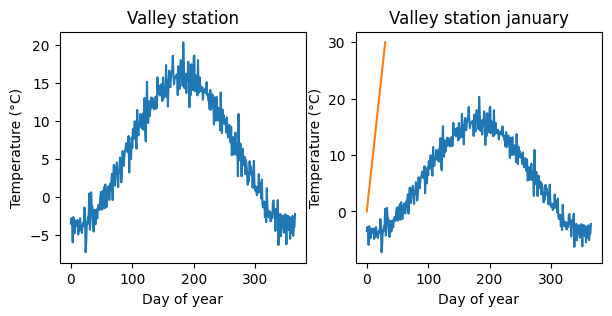

In [2]:
#this was my first code
fig, axes = plt.subplots(figsize=(7, 3), ncols=2)
ax0, ax1 = axes

ax0.plot(days, valley_celsius)
ax0.set_xlabel("Day of year")
ax0.set_ylabel("Temperature (°C)")
ax0.set_title("Valley station")

ax1.plot(days, valley_celsius, days[:31])
ax1.set_xlabel("Day of year")
ax1.set_ylabel("Temperature (°C)")
ax1.set_title("Valley station january")

As we can see my graph isn't what is asked. It's a simple code to do but I didn't read the parameters right and got it wrong.

1. The second graph is the same size as the first one and I don't place the graphs by hand. I used `plt.subplots(ncols=2)` as a reflex because I thought to generate two graphs. So the small graph isn't generated and it only generates a regular grid.
2. The second plot is wrong because matplotlib reads it as `plot(x, y, fmt)`. Here I give it as a array so it doesn't work. With `days[:31]` was interpreted as a second set of y-values, plotted against 0, 1, 2… I needed to trim x and y by the same range: `plot(days[:31], valley_celsius[:31])`.

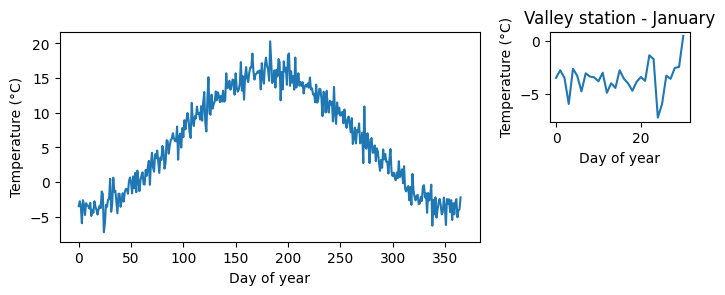

In [3]:
#The code rework

fig = plt.figure(figsize=(7, 3)) #plot by 7x3 inches

ax_main = fig.add_axes([0.1, 0.2, 0.6, 0.7])   # the parameters to fix the graphs in the right place
ax_small = fig.add_axes([0.8, 0.6, 0.2, 0.3])  # I modified the parameters to know where to put the graphs as each number moves the graph on the plot

ax_main.plot(days, valley_celsius) # the first graph for the whole year
ax_main.set_xlabel("Day of year")
ax_main.set_ylabel("Temperature (°C)")

ax_small.plot(days[:31], valley_celsius[:31]) # the limits on the plot to show only January
ax_small.set_xlabel("Day of year")
ax_small.set_ylabel("Temperature (°C)")
ax_small.set_title("Valley station - January") # I added a title on the small plot as asked

plt.show() # shows the figure

I fixed the graph using `fig.add_axes` to place manually the graphs on the plot.
Also `ax_small.plot(days[:31], valley_celsius[:31])` was missing to have the right time of the year displayed.